# Questão 2: Rede MLP para classificar a qualidade de vinhos

Nesta questão usamos uma rede MLP para prever a qualidade de um vinho a partir das suas características químicas (acidez, álcool, pH, densidade etc.). A base é a Wine Quality, da UCI, com vinhos tintos e brancos portugueses.

Cada vinho recebeu uma nota de 0 a 10. Como pede o enunciado, transformamos essa nota em três categorias:
- baixa: notas de 0 a 4;
- média: notas 5 e 6;
- alta: notas de 7 a 10.

Assim o problema vira uma classificação com 3 classes.

## Bibliotecas

In [1]:
import copy
import io
import random
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm

# usa a placa de vídeo se tiver, senão usa o processador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

PASTA_DADOS = Path("../data/wine")
PASTA_FIGURAS = Path("../figures/q2")
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

CLASSES = ["baixa", "média", "alta"]

Rodando em: cuda


## Funções

Aqui ficam todas as funções que usamos no notebook. Cada uma tem uma explicação curta logo acima.

### fixar_semente
Fixa a "semente" dos sorteios (pesos iniciais da rede, embaralhamento dos dados) para que o resultado seja o mesmo toda vez que o notebook for executado.

In [2]:
def fixar_semente(semente=42):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)
    torch.cuda.manual_seed_all(semente)

### carregar_vinhos
Baixa a base do site da UCI (só na primeira vez; depois usa o arquivo salvo na pasta `data`). A base vem em dois arquivos, um de vinhos tintos e outro de brancos. Juntamos os dois em uma tabela só e criamos a coluna `tinto` (1 para tinto, 0 para branco), para a rede saber de qual tipo é cada vinho.

In [3]:
def carregar_vinhos():
    arquivo_zip = PASTA_DADOS / "wine.zip"
    if not arquivo_zip.exists():
        PASTA_DADOS.mkdir(parents=True, exist_ok=True)
        url = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
        urllib.request.urlretrieve(url, arquivo_zip)

    with zipfile.ZipFile(arquivo_zip) as z:
        tintos = pd.read_csv(io.BytesIO(z.read("winequality-red.csv")), sep=";")
        brancos = pd.read_csv(io.BytesIO(z.read("winequality-white.csv")), sep=";")
    tintos["tinto"] = 1
    brancos["tinto"] = 0
    return pd.concat([tintos, brancos], ignore_index=True)

### nota_para_classe
Transforma a nota (0 a 10) no número da classe: 0 para baixa (até 4), 1 para média (5 e 6) e 2 para alta (7 ou mais).

In [4]:
def nota_para_classe(nota):
    if nota <= 4:
        return 0
    if nota <= 6:
        return 1
    return 2

### calcular_vif
Mede se uma coluna é redundante, ou seja, se ela pode ser "adivinhada" a partir das outras colunas. Para cada coluna, treinamos uma regressão linear que tenta prever essa coluna usando todas as outras e calculamos o VIF = 1 / (1 - R²).
- VIF perto de 1: a coluna traz informação nova.
- VIF acima de 10: a coluna é quase uma combinação das outras, então é redundante.

In [5]:
def calcular_vif(tabela):
    vif = {}
    for coluna in tabela.columns:
        outras = tabela.drop(columns=coluna)
        r2 = LinearRegression().fit(outras, tabela[coluna]).score(outras, tabela[coluna])
        vif[coluna] = 1 / (1 - r2)
    return pd.Series(vif).sort_values(ascending=False)

### criar_loader
Transforma os arrays em um "loader", que entrega os dados em lotes para o PyTorch. As classes são números inteiros (0, 1 ou 2), por isso o `y` vira um tensor do tipo `long`.

In [6]:
def criar_loader(X, y, tamanho_lote, embaralhar):
    dados = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
    return DataLoader(dados, batch_size=tamanho_lote, shuffle=embaralhar)

### MLP
A nossa rede. Recebe o número de entradas, a lista de camadas escondidas e o dropout. A saída tem 3 neurônios, um para cada classe. O neurônio com o maior valor é a classe prevista.

A última camada não tem softmax de propósito: a função de erro que usamos (CrossEntropyLoss) já aplica o softmax por dentro.

In [7]:
class MLP(nn.Module):
    def __init__(self, entradas, camadas, saidas=3, dropout=0.0):
        super().__init__()
        partes = []
        anterior = entradas
        for neuronios in camadas:
            partes.append(nn.Linear(anterior, neuronios))
            partes.append(nn.ReLU())
            if dropout > 0:
                partes.append(nn.Dropout(dropout))
            anterior = neuronios
        partes.append(nn.Linear(anterior, saidas))
        self.rede = nn.Sequential(*partes)

    def forward(self, x):
        return self.rede(x)

### rodar_epoca
Passa uma vez por todos os lotes de um loader. Devolve o erro médio (entropia cruzada) e as classes previstas para cada exemplo.
- Com otimizador, a rede aprende (ajusta os pesos).
- Sem otimizador, a rede só é avaliada.

In [8]:
def rodar_epoca(modelo, loader, funcao_erro, otimizador=None):
    treinando = otimizador is not None
    modelo.train(treinando)
    erro_total = 0.0
    previstos, reais = [], []
    with torch.set_grad_enabled(treinando):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            saida = modelo(x)
            erro = funcao_erro(saida, y)
            if treinando:
                otimizador.zero_grad()
                erro.backward()
                otimizador.step()
            erro_total += erro.item() * len(x)
            previstos.append(saida.argmax(dim=1).cpu())
            reais.append(y.cpu())
    return erro_total / len(loader.dataset), torch.cat(reais).numpy(), torch.cat(previstos).numpy()

### treinar
Treina a rede com o otimizador Adam. A cada época:
1. a rede aprende com os dados de treino;
2. medimos o erro e o F1 macro na validação;
3. guardamos os pesos da época com o maior F1 macro na validação.

Por que F1 macro e não acurácia? Como 77% dos vinhos são de qualidade média, uma rede que sempre responde "média" já acerta 77%. O F1 macro dá o mesmo peso para as três classes, então ele só fica alto se a rede acertar também os vinhos de qualidade baixa e alta.

Se o F1 da validação ficar `paciencia` épocas sem melhorar, o treino para (early stopping).

`pesos_classes` é usado em uma das estratégias de balanceamento: o erro de cada classe é multiplicado por um peso, para que errar uma classe rara "custe" mais.

In [9]:
def treinar(modelo, loader_treino, loader_val, epocas, lr=1e-3, weight_decay=0.0,
            paciencia=None, pesos_classes=None, nome="Treinando"):
    if pesos_classes is not None:
        pesos_classes = torch.tensor(pesos_classes, dtype=torch.float32, device=device)
    funcao_erro = nn.CrossEntropyLoss(weight=pesos_classes)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)

    historico = {"treino": [], "val": [], "f1_treino": [], "f1_val": [], "melhor_epoca": 0}
    melhor_f1 = -1.0
    melhores_pesos = None
    epocas_sem_melhorar = 0

    barra = tqdm(range(1, epocas + 1), desc=nome, unit="época", ncols=110, mininterval=2)
    for epoca in barra:
        erro_treino, reais_tr, previstos_tr = rodar_epoca(modelo, loader_treino, funcao_erro, otimizador)
        erro_val, reais_val, previstos_val = rodar_epoca(modelo, loader_val, funcao_erro)
        f1_treino = f1_score(reais_tr, previstos_tr, average="macro")
        f1_val = f1_score(reais_val, previstos_val, average="macro")

        historico["treino"].append(erro_treino)
        historico["val"].append(erro_val)
        historico["f1_treino"].append(f1_treino)
        historico["f1_val"].append(f1_val)

        if f1_val > melhor_f1:
            melhor_f1 = f1_val
            melhores_pesos = copy.deepcopy(modelo.state_dict())
            historico["melhor_epoca"] = epoca
            epocas_sem_melhorar = 0
        else:
            epocas_sem_melhorar += 1

        barra.set_postfix(erro_treino=f"{erro_treino:.3f}", erro_val=f"{erro_val:.3f}",
                          f1_val=f"{f1_val:.3f}", melhor=historico["melhor_epoca"], refresh=False)

        if paciencia is not None and epocas_sem_melhorar >= paciencia:
            barra.close()
            print(f"Parou na época {epoca}: o F1 da validação ficou {paciencia} épocas sem melhorar.")
            break

    # se o erro virou NaN (treino "explodiu"), nenhuma época foi guardada
    if melhores_pesos is None:
        raise RuntimeError("O F1 de validação nunca foi calculado direito. Tente uma taxa de aprendizado menor.")

    modelo.load_state_dict(melhores_pesos)
    print(f"Melhor época: {historico['melhor_epoca']} (F1 macro na validação = {melhor_f1:.3f})")
    return historico

### prever
Devolve a classe prevista pela rede para cada vinho e também a probabilidade de cada classe (aplicando o softmax na saída).

In [10]:
def prever(modelo, X):
    modelo.eval()
    with torch.no_grad():
        saida = modelo(torch.tensor(X, dtype=torch.float32, device=device))
        probabilidades = torch.softmax(saida, dim=1).cpu().numpy()
    return probabilidades.argmax(axis=1), probabilidades

### calcular_metricas
Calcula as métricas pedidas na questão:
- acurácia: porcentagem de vinhos classificados corretamente;
- precisão: dos vinhos que a rede disse ser de uma classe, quantos realmente são;
- recall: dos vinhos que são de uma classe, quantos a rede encontrou;
- F1: média entre precisão e recall (só é alto se as duas forem altas).

Precisão, recall e F1 são calculados para cada classe e depois tiramos a média simples das três (média "macro"), para que a classe rara pese o mesmo que a classe comum.

In [11]:
def calcular_metricas(y_real, y_previsto):
    return {
        "acurácia": accuracy_score(y_real, y_previsto),
        "precisão (macro)": precision_score(y_real, y_previsto, average="macro", zero_division=0),
        "recall (macro)": recall_score(y_real, y_previsto, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_real, y_previsto, average="macro", zero_division=0),
    }

### grafico_curvas
Desenha, lado a lado, o erro (entropia cruzada) e o F1 macro de treino e de validação ao longo das épocas. A linha tracejada marca a melhor época, cujos pesos a rede usa no final.

In [12]:
def grafico_curvas(historico, titulo, arquivo=None):
    epocas = range(1, len(historico["treino"]) + 1)
    melhor = historico["melhor_epoca"]
    fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(13, 4.5))
    esquerda.plot(epocas, historico["treino"], label="treino")
    esquerda.plot(epocas, historico["val"], label="validação")
    esquerda.set_ylabel("erro (entropia cruzada)")
    direita.plot(epocas, historico["f1_treino"], label="treino")
    direita.plot(epocas, historico["f1_val"], label="validação")
    direita.set_ylabel("F1 macro")
    for eixo in (esquerda, direita):
        eixo.axvline(melhor, color="gray", linestyle="--", label=f"melhor época ({melhor})")
        eixo.set_xlabel("época")
        eixo.legend()
        eixo.grid(alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

### grafico_matriz_confusao
Desenha a matriz de confusão. Cada linha é a classe real e cada coluna é a classe que a rede previu. A diagonal são os acertos. À esquerda mostramos as quantidades e à direita a porcentagem de cada linha (ou seja, o recall de cada classe na diagonal).

In [13]:
def grafico_matriz_confusao(y_real, y_previsto, titulo, arquivo=None):
    matriz = confusion_matrix(y_real, y_previsto)
    porcentagem = matriz / matriz.sum(axis=1, keepdims=True)
    fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=esquerda)
    sns.heatmap(porcentagem, annot=True, fmt=".0%", cmap="Blues", cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=direita)
    esquerda.set_title("Quantidade de vinhos")
    direita.set_title("Porcentagem de cada classe real")
    for eixo in (esquerda, direita):
        eixo.set_xlabel("classe prevista")
        eixo.set_ylabel("classe real")
    fig.suptitle(titulo)
    plt.tight_layout()
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

### criar_modelo e treinar_modelo
A mesma rede e o mesmo jeito de treinar são usados em todas as estratégias de balanceamento. Assim a única diferença entre elas é o balanceamento.
- `criar_modelo`: rede com 128 e 64 neurônios nas camadas escondidas, ReLU e dropout de 30%.
- `treinar_modelo`: até 300 épocas, taxa de aprendizado 0,001, weight decay 0,0001, lotes de 64 vinhos e parada se o F1 da validação ficar 40 épocas sem melhorar.

In [14]:
def criar_modelo(entradas):
    fixar_semente()
    return MLP(entradas=entradas, camadas=[128, 64], dropout=0.3).to(device)


def treinar_modelo(modelo, X_treino, y_treino, X_val, y_val, pesos_classes=None, nome="Treinando"):
    fixar_semente()
    loader_treino = criar_loader(X_treino, y_treino, tamanho_lote=64, embaralhar=True)
    loader_val = criar_loader(X_val, y_val, tamanho_lote=512, embaralhar=False)
    return treinar(modelo, loader_treino, loader_val, epocas=300, lr=1e-3, weight_decay=1e-4,
                   paciencia=40, pesos_classes=pesos_classes, nome=nome)

---
# Análise exploratória

## Carregando a base

In [15]:
vinhos = carregar_vinhos()
print("Tamanho da tabela:", vinhos.shape)
vinhos.head()

Tamanho da tabela: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tinto
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


Cada linha é um vinho. As colunas são:
- fixed acidity: acidez fixa
- volatile acidity: acidez volátil (em excesso dá gosto de vinagre)
- citric acid: ácido cítrico
- residual sugar: açúcar que sobra depois da fermentação
- chlorides: cloretos (sal)
- free sulfur dioxide e total sulfur dioxide: dióxido de enxofre livre e total (conservante)
- density: densidade
- pH
- sulphates: sulfatos
- alcohol: teor alcoólico
- quality: a nota do vinho (o que queremos prever)
- tinto: coluna que criamos (1 = tinto, 0 = branco)

## Valores ausentes

In [16]:
vinhos.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
tinto                   0
dtype: int64

Nenhuma coluna tem valor ausente. Não é preciso preencher nem remover nada por esse motivo.

## Linhas repetidas

In [17]:
print("Linhas repetidas:", vinhos.duplicated().sum())
vinhos = vinhos.drop_duplicates().reset_index(drop=True)
print("Tamanho depois de remover as repetidas:", vinhos.shape)

Linhas repetidas: 1177
Tamanho depois de remover as repetidas: (5320, 13)


A base tem 1177 linhas repetidas (vinhos com exatamente os mesmos valores em todas as colunas). Removemos essas linhas por dois motivos:
- elas não trazem informação nova;
- se uma cópia cair no treino e a outra no teste, a rede é testada num vinho que ela já viu, e o resultado fica melhor do que deveria.

## Estatísticas de cada coluna

In [18]:
vinhos.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.22,1.32,3.80,6.40,7.00,7.70,15.90
volatile acidity,5320.0,0.34,0.17,0.08,0.23,0.30,0.41,1.58
citric acid,5320.0,0.32,0.15,0.00,0.24,0.31,0.40,1.66
residual sugar,5320.0,5.05,4.50,0.60,1.80,2.70,7.50,65.80
chlorides,5320.0,0.06,0.04,0.01,0.04,0.05,0.07,0.61
free sulfur dioxide,5320.0,30.04,17.81,1.00,16.00,28.00,41.00,289.00
total sulfur dioxide,5320.0,114.11,56.77,6.00,74.00,116.00,153.25,440.00
density,5320.0,0.99,0.00,0.99,0.99,0.99,1.00,1.04
pH,5320.0,3.22,0.16,2.72,3.11,3.21,3.33,4.01
sulphates,5320.0,0.53,0.15,0.22,0.43,0.51,0.60,2.00


As colunas estão em escalas muito diferentes. O total sulfur dioxide vai de 6 a 440, enquanto a densidade fica entre 0,99 e 1,04 e os cloretos entre 0,01 e 0,61. Por isso vamos normalizar antes de treinar a rede.

## Criando as três classes de qualidade

In [19]:
vinhos["classe"] = vinhos["quality"].apply(nota_para_classe)

contagem_notas = vinhos["quality"].value_counts().sort_index()
contagem_classes = vinhos["classe"].value_counts().sort_index()
contagem_classes.index = CLASSES
pd.DataFrame({"vinhos": contagem_classes, "porcentagem": (contagem_classes / len(vinhos) * 100).round(1)})

,vinhos,porcentagem
baixa,236,4.4
média,4075,76.6
alta,1009,19.0


## Distribuição das notas e das classes

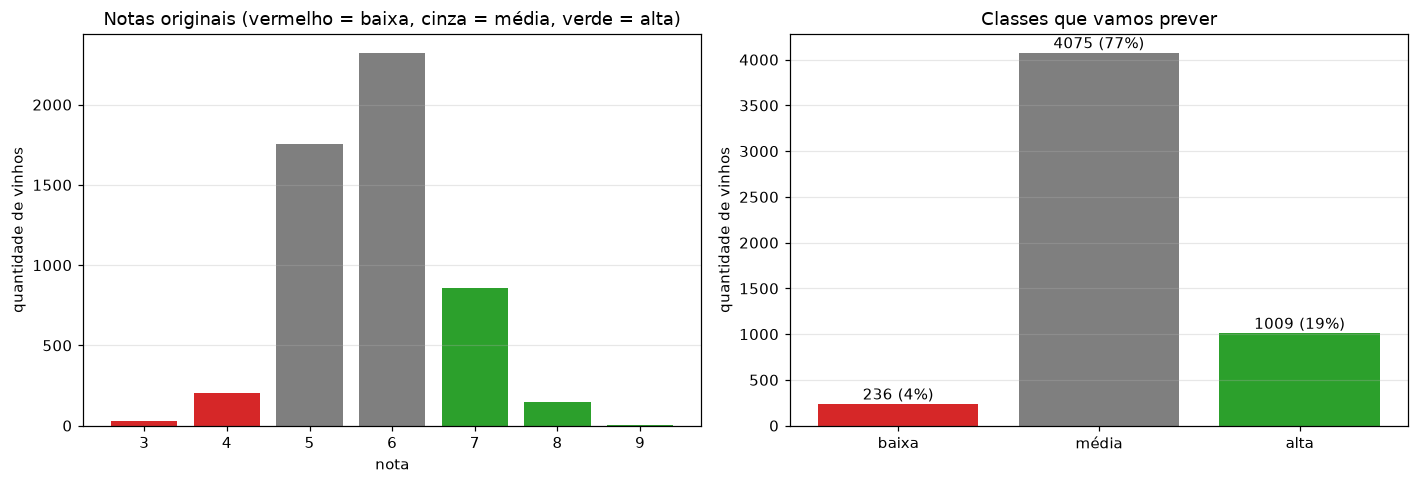

In [20]:
fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(13, 4.5))
cores_notas = ["tab:red" if n <= 4 else "tab:gray" if n <= 6 else "tab:green" for n in contagem_notas.index]
esquerda.bar(contagem_notas.index, contagem_notas.values, color=cores_notas)
esquerda.set_xlabel("nota")
esquerda.set_ylabel("quantidade de vinhos")
esquerda.set_title("Notas originais (vermelho = baixa, cinza = média, verde = alta)")
direita.bar(CLASSES, contagem_classes.values, color=["tab:red", "tab:gray", "tab:green"])
for i, valor in enumerate(contagem_classes.values):
    direita.text(i, valor + 50, f"{valor} ({valor / len(vinhos):.0%})", ha="center")
direita.set_ylabel("quantidade de vinhos")
direita.set_title("Classes que vamos prever")
for eixo in (esquerda, direita):
    eixo.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "2_classes.png", bbox_inches="tight")
plt.show()

O que observar:
- Quase todos os vinhos têm nota 5 ou 6. Notas extremas são raras: só uns 30 vinhos com nota 3 e 5 com nota 9. Nenhum vinho tem nota 0, 1, 2 ou 10.
- Depois de agrupar, as classes ficam muito desbalanceadas: 77% média, 19% alta e só 4% baixa (236 vinhos).
- Isso significa que uma rede "preguiçosa", que sempre responde "média", acertaria 77% dos vinhos sem aprender nada. Por isso a acurácia sozinha não serve para avaliar o modelo, e vamos olhar principalmente o F1 macro e o recall de cada classe.

## Distribuição de cada atributo

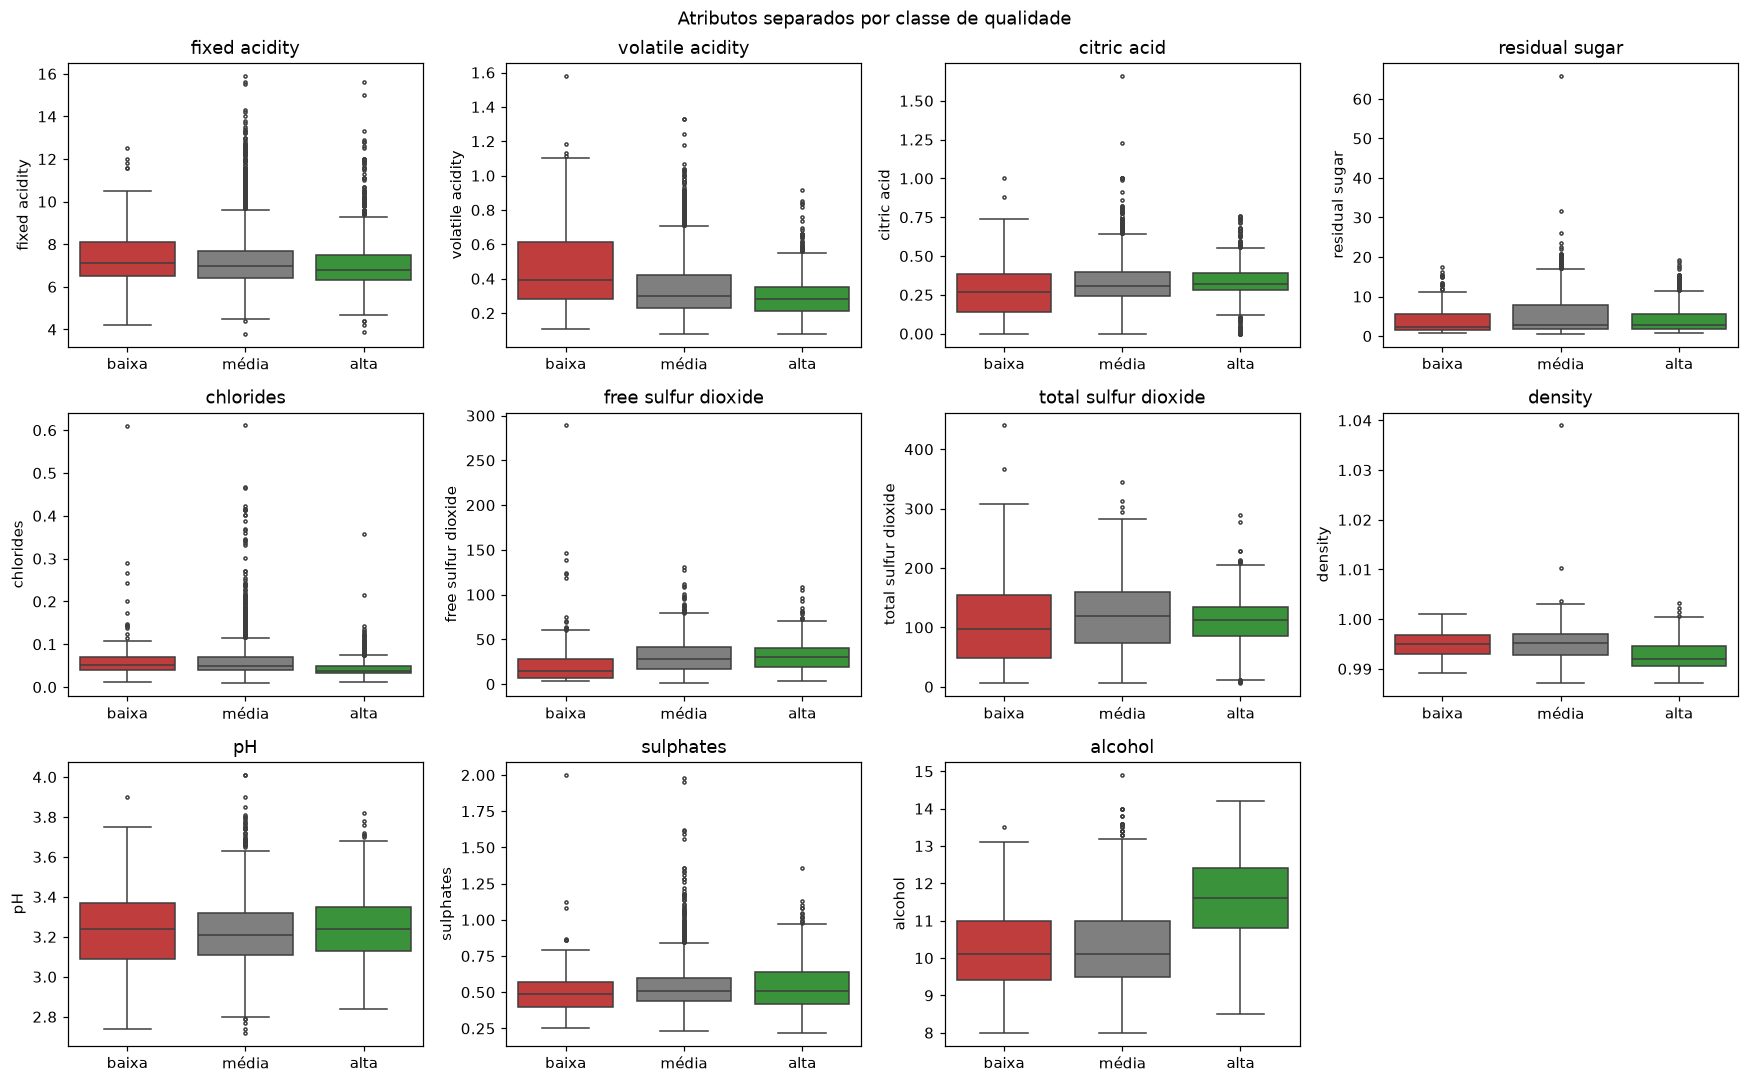

In [21]:
atributos = vinhos.columns.drop(["quality", "classe", "tinto"])
nome_classe = vinhos["classe"].map(dict(enumerate(CLASSES)))
cores = {"baixa": "tab:red", "média": "tab:gray", "alta": "tab:green"}

fig, eixos = plt.subplots(3, 4, figsize=(16, 10))
for eixo, coluna in zip(eixos.flat, atributos):
    sns.boxplot(x=nome_classe, y=vinhos[coluna], order=CLASSES, hue=nome_classe,
                palette=cores, legend=False, ax=eixo, fliersize=2)
    eixo.set_xlabel("")
    eixo.set_title(coluna)
eixos.flat[-1].axis("off")
plt.suptitle("Atributos separados por classe de qualidade")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "2_boxplots.png", bbox_inches="tight")
plt.show()

Como ler: a caixa mostra onde está a metade do meio dos vinhos, a linha dentro dela é a mediana e as bolinhas são valores muito fora do comum (outliers).

O que observar:
- O álcool é o atributo que mais separa as classes: os vinhos de qualidade alta têm mediana de cerca de 11,6% de álcool, contra cerca de 10,1% dos médios e baixos.
- A acidez volátil é mais alta nos vinhos de qualidade baixa (mediana perto de 0,40, contra 0,28 nos altos). Faz sentido: acidez volátil em excesso dá gosto de vinagre.
- A densidade é um pouco menor nos vinhos de qualidade alta, e os cloretos também.
- Nos outros atributos as caixas das três classes ficam quase na mesma altura, ou seja, sozinhos eles ajudam pouco a separar as classes.
- Quase todos os atributos têm muitos outliers (por exemplo, açúcar residual de 65 e dióxido de enxofre livre de 289). Não removemos esses vinhos, porque são valores possíveis e não erros de medição. A normalização ajuda a rede a lidar com essas escalas diferentes.
- As caixas das três classes se sobrepõem bastante em todos os atributos. Isso já indica que separar as classes vai ser difícil.

## Correlação entre os atributos

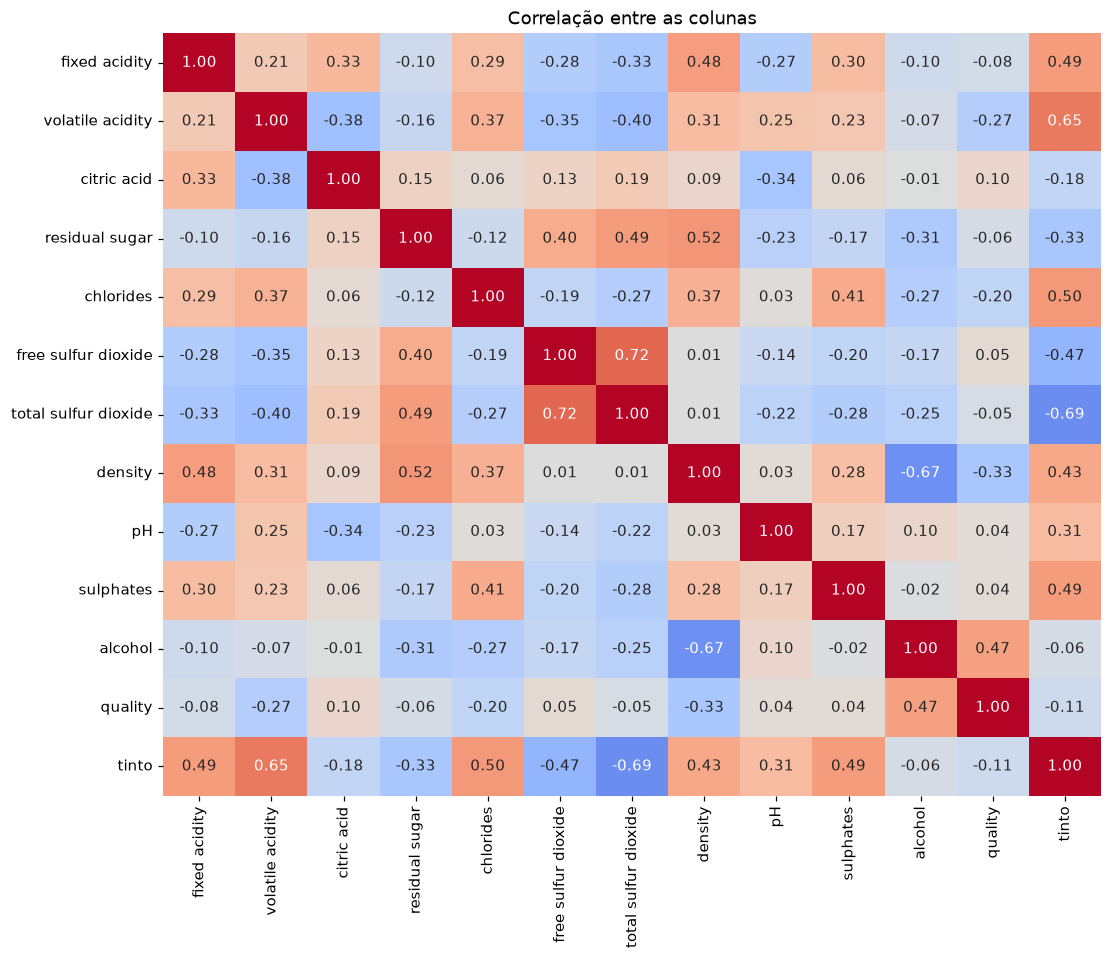

In [22]:
correlacao = vinhos.drop(columns="classe").corr()

plt.figure(figsize=(11, 9))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=False)
plt.title("Correlação entre as colunas")
plt.savefig(PASTA_FIGURAS / "2_correlacao.png", bbox_inches="tight")
plt.show()

O que observar:
- Na linha quality, o atributo mais ligado à nota é o álcool (0,47), seguido da densidade (-0,33) e da acidez volátil (-0,27). Todos os outros têm correlação fraca com a nota.
- Alguns pares de atributos andam juntos: dióxido de enxofre livre e total (0,72) e densidade com álcool (-0,67) e com açúcar residual (0,52).
- A coluna tinto tem correlação forte com vários atributos (acidez volátil 0,65 e dióxido de enxofre total -0,69). Vinhos tintos e brancos têm composições bem diferentes, e é por isso que é importante a rede saber o tipo de cada vinho.

## Atributos redundantes
A correlação compara as colunas só de duas em duas. Uma coluna também pode ser redundante por ser uma combinação de várias outras. Para verificar isso usamos o VIF (explicado na seção de funções).

In [23]:
vif = calcular_vif(vinhos.drop(columns=["quality", "classe"]))
vif.round(1)

density                 20.7
residual sugar           8.4
tinto                    7.0
alcohol                  5.3
fixed acidity            5.0
total sulfur dioxide     4.0
pH                       2.5
free sulfur dioxide      2.2
volatile acidity         2.2
citric acid              1.7
chlorides                1.7
sulphates                1.6
dtype: float64

A densidade tem VIF de 20,7, bem acima de 10. Isso quer dizer que ela pode ser calculada quase perfeitamente a partir dos outros atributos. Faz sentido físico: a densidade do vinho depende principalmente de quanto álcool (mais leve que a água) e quanto açúcar (mais pesado) ele tem.

Por isso removemos a densidade. Ela não traz informação nova e só repete o que o álcool e o açúcar já dizem.

Um detalhe: o VIF foi calculado com a base inteira, antes de separar o teste. Como ele só olha a relação entre os atributos (e não a nota), e a densidade está muito acima do limite, a decisão seria a mesma usando só o treino.

In [24]:
vinhos = vinhos.drop(columns="density")
print("VIF depois de remover a densidade:")
calcular_vif(vinhos.drop(columns=["quality", "classe"])).round(1)

VIF depois de remover a densidade:


tinto                   5.0
total sulfur dioxide    4.0
free sulfur dioxide     2.2
fixed acidity           2.2
volatile acidity        2.1
citric acid             1.7
chlorides               1.6
pH                      1.6
sulphates               1.5
residual sugar          1.4
alcohol                 1.4
dtype: float64

Sem a densidade, todos os atributos ficam com VIF abaixo de 5. O açúcar residual, por exemplo, caiu de 8,4 para 1,4, porque a parte "repetida" dele estava ligada à densidade.

O dióxido de enxofre livre e o total têm correlação de 0,72, mas o VIF deles é baixo (2,2 e 4,0). Então mantemos os dois: um mede só a parte livre e o outro mede tudo.

---
# Pré-processamento

## Separando entradas e saída
A coluna quality não pode entrar como entrada, porque a classe é calculada a partir dela.

In [25]:
X = vinhos.drop(columns=["quality", "classe"]).values
y = vinhos["classe"].values
nomes_atributos = vinhos.drop(columns=["quality", "classe"]).columns.tolist()
print("Entradas:", X.shape)
print("Atributos usados:", nomes_atributos)

Entradas: (5320, 11)
Atributos usados: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'pH', 'sulphates', 'alcohol', 'tinto']


## Dividindo em treino, validação e teste
Separamos 70% para treino, 15% para validação e 15% para teste. A divisão é estratificada: cada parte fica com a mesma proporção de vinhos baixos, médios e altos. Sem isso, a classe baixa, que é rara, poderia ficar com pouquíssimos exemplos na validação ou no teste.

In [26]:
X_treino, X_resto, y_treino, y_resto = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_teste, y_val, y_teste = train_test_split(X_resto, y_resto, test_size=0.50, stratify=y_resto, random_state=42)

pd.DataFrame({
    "treino": np.bincount(y_treino),
    "validação": np.bincount(y_val),
    "teste": np.bincount(y_teste),
}, index=CLASSES)

,treino,validação,teste
baixa,165,35,36
média,2853,611,611
alta,706,152,151


## Normalizando
Deixamos cada atributo com média 0 e desvio padrão 1. A média e o desvio são calculados só com o treino.

In [27]:
normalizador = StandardScaler().fit(X_treino)
X_treino_n = normalizador.transform(X_treino)
X_val_n = normalizador.transform(X_val)
X_teste_n = normalizador.transform(X_teste)

---
# Balanceamento das classes

Só 4% dos vinhos são de qualidade baixa. Se treinarmos a rede sem fazer nada, ela tende a quase nunca responder "baixa", porque errar esses poucos vinhos quase não aumenta o erro total.

Para ver se precisamos de balanceamento, treinamos a mesma rede de quatro jeitos e comparamos na validação:
1. sem balanceamento;
2. com pesos nas classes: o erro de cada vinho é multiplicado por um peso maior quanto mais rara for a classe dele;
3. com pesos suavizados: a mesma ideia, mas usando a raiz quadrada dos pesos, para a diferença entre as classes não ser tão grande;
4. com SMOTE: criamos vinhos "artificiais" das classes raras no treino, misturando vinhos parecidos que já existem, até as três classes terem a mesma quantidade.

O balanceamento é feito só no treino. Validação e teste continuam com as proporções reais, porque é assim que os vinhos aparecem no mundo real.

## Estratégia 1: sem balanceamento

In [28]:
modelo_sem = criar_modelo(X_treino_n.shape[1])
historico_sem = treinar_modelo(modelo_sem, X_treino_n, y_treino, X_val_n, y_val, nome="Sem balanceamento")

Sem balanceamento:   0%|                                                           | 0/300 [00:00<?, ?época/s]

Sem balanceamento:   4%| | 12/300 [00:02<00:51,  5.62época/s, erro_treino=0.512, erro_val=0.491, f1_val=0.480,

Sem balanceamento:   8%| | 25/300 [00:04<00:46,  5.87época/s, erro_treino=0.490, erro_val=0.484, f1_val=0.501,

Sem balanceamento:  12%| | 37/300 [00:06<00:44,  5.90época/s, erro_treino=0.471, erro_val=0.487, f1_val=0.504,

Sem balanceamento:  16%|▏| 49/300 [00:08<00:44,  5.67época/s, erro_treino=0.460, erro_val=0.484, f1_val=0.529,

Sem balanceamento:  20%|▏| 61/300 [00:10<00:43,  5.49época/s, erro_treino=0.451, erro_val=0.485, f1_val=0.528,

Sem balanceamento:  24%|▏| 73/300 [00:13<00:41,  5.52época/s, erro_treino=0.449, erro_val=0.492, f1_val=0.482,

Sem balanceamento:  28%|▎| 85/300 [00:15<00:39,  5.49época/s, erro_treino=0.445, erro_val=0.489, f1_val=0.531,

Sem balanceamento:  28%|▎| 85/300 [00:16<00:42,  5.11época/s, erro_treino=0.433, erro_val=0.496, f1_val=0.524,

Parou na época 92: o F1 da validação ficou 40 épocas sem melhorar.
Melhor época: 52 (F1 macro na validação = 0.550)


## Estratégia 2: pesos nas classes

In [29]:
pesos = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_treino)
print("Peso de cada classe:", dict(zip(CLASSES, pesos.round(2))))

Peso de cada classe: {'baixa': np.float64(7.52), 'média': np.float64(0.44), 'alta': np.float64(1.76)}


In [30]:
modelo_pesos = criar_modelo(X_treino_n.shape[1])
historico_pesos = treinar_modelo(modelo_pesos, X_treino_n, y_treino, X_val_n, y_val,
                                 pesos_classes=pesos, nome="Pesos nas classes")

Pesos nas classes:   0%|                                                           | 0/300 [00:00<?, ?época/s]

Pesos nas classes:   4%| | 11/300 [00:02<00:57,  5.00época/s, erro_treino=0.747, erro_val=0.767, f1_val=0.526,

Pesos nas classes:   7%| | 21/300 [00:04<00:57,  4.83época/s, erro_treino=0.715, erro_val=0.750, f1_val=0.537,

Pesos nas classes:  10%| | 31/300 [00:06<00:57,  4.65época/s, erro_treino=0.681, erro_val=0.786, f1_val=0.545,

Pesos nas classes:  14%|▏| 41/300 [00:08<00:56,  4.55época/s, erro_treino=0.658, erro_val=0.792, f1_val=0.518,

Pesos nas classes:  17%|▏| 51/300 [00:11<00:58,  4.28época/s, erro_treino=0.633, erro_val=0.831, f1_val=0.544,

Pesos nas classes:  20%|▏| 60/300 [00:13<00:56,  4.27época/s, erro_treino=0.625, erro_val=0.845, f1_val=0.519,

Pesos nas classes:  24%|▏| 71/300 [00:15<00:49,  4.63época/s, erro_treino=0.599, erro_val=0.904, f1_val=0.532,

Pesos nas classes:  24%|▏| 71/300 [00:16<00:53,  4.24época/s, erro_treino=0.604, erro_val=0.907, f1_val=0.523,

Parou na época 77: o F1 da validação ficou 40 épocas sem melhorar.
Melhor época: 37 (F1 macro na validação = 0.555)


## Estratégia 3: pesos suavizados
Com os pesos da estratégia 2, errar um vinho de qualidade baixa custa 17 vezes mais do que errar um vinho médio (7,52 contra 0,44). Isso pode fazer a rede exagerar e começar a chamar muitos vinhos médios de baixos. Tirando a raiz quadrada, a diferença cai para cerca de 4 vezes.

In [31]:
pesos_suaves = np.sqrt(pesos)
print("Peso de cada classe:", dict(zip(CLASSES, pesos_suaves.round(2))))

Peso de cada classe: {'baixa': np.float64(2.74), 'média': np.float64(0.66), 'alta': np.float64(1.33)}


In [32]:
modelo_suave = criar_modelo(X_treino_n.shape[1])
historico_suave = treinar_modelo(modelo_suave, X_treino_n, y_treino, X_val_n, y_val,
                                 pesos_classes=pesos_suaves, nome="Pesos suavizados")

Pesos suavizados:   0%|                                                            | 0/300 [00:00<?, ?época/s]

Pesos suavizados:   4%| | 11/300 [00:02<00:56,  5.08época/s, erro_treino=0.702, erro_val=0.688, f1_val=0.574, 

Pesos suavizados:   7%| | 22/300 [00:04<00:55,  5.00época/s, erro_treino=0.659, erro_val=0.678, f1_val=0.584, 

Pesos suavizados:  11%| | 32/300 [00:06<00:57,  4.69época/s, erro_treino=0.641, erro_val=0.687, f1_val=0.587, 

Pesos suavizados:  14%|▏| 43/300 [00:08<00:53,  4.85época/s, erro_treino=0.622, erro_val=0.691, f1_val=0.584, 

Pesos suavizados:  18%|▏| 54/300 [00:10<00:49,  4.96época/s, erro_treino=0.608, erro_val=0.693, f1_val=0.580, 

Pesos suavizados:  22%|▏| 66/300 [00:13<00:45,  5.16época/s, erro_treino=0.586, erro_val=0.705, f1_val=0.567, 

Pesos suavizados:  22%|▏| 66/300 [00:13<00:49,  4.75época/s, erro_treino=0.584, erro_val=0.710, f1_val=0.577, 

Parou na época 70: o F1 da validação ficou 40 épocas sem melhorar.
Melhor época: 30 (F1 macro na validação = 0.603)


## Estratégia 4: SMOTE

In [33]:
X_treino_smote, y_treino_smote = SMOTE(random_state=42).fit_resample(X_treino_n, y_treino)
print("Vinhos no treino antes do SMOTE:", dict(zip(CLASSES, np.bincount(y_treino))))
print("Vinhos no treino depois do SMOTE:", dict(zip(CLASSES, np.bincount(y_treino_smote))))

Vinhos no treino antes do SMOTE: {'baixa': np.int64(165), 'média': np.int64(2853), 'alta': np.int64(706)}
Vinhos no treino depois do SMOTE: {'baixa': np.int64(2853), 'média': np.int64(2853), 'alta': np.int64(2853)}


In [34]:
modelo_smote = criar_modelo(X_treino_n.shape[1])
historico_smote = treinar_modelo(modelo_smote, X_treino_smote, y_treino_smote, X_val_n, y_val, nome="SMOTE")

SMOTE:   0%|                                                                       | 0/300 [00:00<?, ?época/s]

SMOTE:   2%|    | 5/300 [00:02<02:07,  2.31época/s, erro_treino=0.653, erro_val=0.754, f1_val=0.522, melhor=2]

SMOTE:   4%|   | 11/300 [00:04<01:54,  2.51época/s, erro_treino=0.587, erro_val=0.735, f1_val=0.529, melhor=9]

SMOTE:   6%|▏  | 17/300 [00:06<01:54,  2.47época/s, erro_treino=0.549, erro_val=0.725, f1_val=0.533, melhor=9]

SMOTE:   7%|▏  | 22/300 [00:09<01:55,  2.41época/s, erro_treino=0.526, erro_val=0.744, f1_val=0.522, melhor=9]

SMOTE:   9%|▎  | 27/300 [00:11<01:52,  2.42época/s, erro_treino=0.503, erro_val=0.735, f1_val=0.516, melhor=9]

... (2 outputs left out)

SMOTE:  14%|▍  | 43/300 [00:17<01:46,  2.41época/s, erro_treino=0.453, erro_val=0.747, f1_val=0.522, melhor=9]

SMOTE:  16%|▍  | 48/300 [00:19<01:44,  2.40época/s, erro_treino=0.443, erro_val=0.731, f1_val=0.527, melhor=9]

SMOTE:  16%|▍  | 48/300 [00:20<01:46,  2.36época/s, erro_treino=0.449, erro_val=0.734, f1_val=0.526, melhor=9]

Parou na época 49: o F1 da validação ficou 40 épocas sem melhorar.
Melhor época: 9 (F1 macro na validação = 0.540)


## Comparando as quatro estratégias na validação
Escolhemos a estratégia olhando só a validação. O teste fica guardado para o final.

In [35]:
estrategias = {"sem balanceamento": modelo_sem, "pesos nas classes": modelo_pesos,
               "pesos suavizados": modelo_suave, "SMOTE": modelo_smote}

comparacao = {}
recall_por_classe = {}
for nome, modelo in estrategias.items():
    previstos_val, _ = prever(modelo, X_val_n)
    comparacao[nome] = calcular_metricas(y_val, previstos_val)
    recall_por_classe[nome] = recall_score(y_val, previstos_val, average=None)

tabela_comparacao = pd.DataFrame(comparacao).T
tabela_recall = pd.DataFrame(recall_por_classe, index=[f"recall {c}" for c in CLASSES]).T
pd.concat([tabela_comparacao, tabela_recall], axis=1).round(3)

,acurácia,precisão (macro),recall (macro),F1 (macro),recall baixa,recall média,recall alta
sem balanceamento,0.798,0.753,0.514,0.550,0.143,0.913,0.487
pesos nas classes,0.683,0.535,0.674,0.555,0.486,0.642,0.895
pesos suavizados,0.778,0.602,0.604,0.603,0.371,0.848,0.592
SMOTE,0.664,0.521,0.665,0.540,0.514,0.625,0.855


## Gráfico da comparação

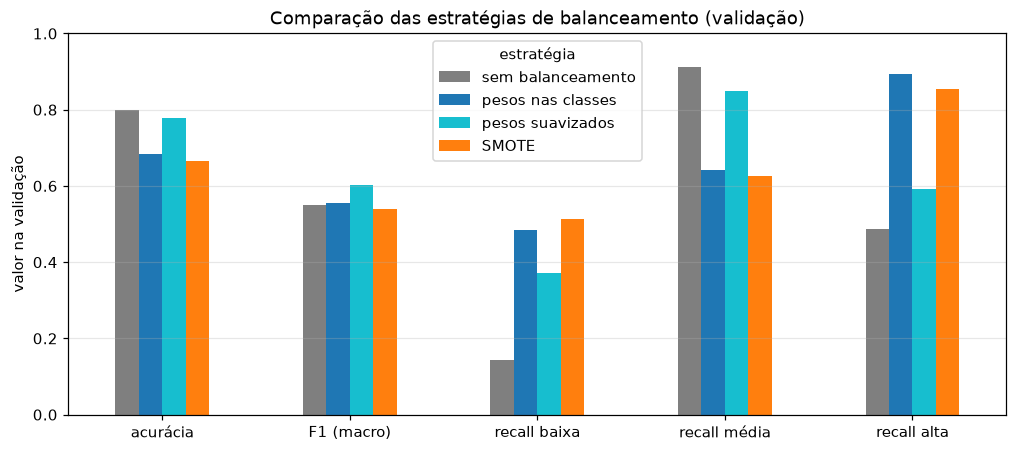

In [36]:
tabela_grafico = pd.concat([tabela_comparacao[["acurácia", "F1 (macro)"]], tabela_recall], axis=1)

tabela_grafico.T.plot.bar(figsize=(11, 4.5), rot=0, color=["tab:gray", "tab:blue", "tab:cyan", "tab:orange"])
plt.ylabel("valor na validação")
plt.title("Comparação das estratégias de balanceamento (validação)")
plt.ylim(0, 1)
plt.grid(alpha=0.3, axis="y")
plt.legend(title="estratégia")
plt.savefig(PASTA_FIGURAS / "2_comparacao_balanceamento.png", bbox_inches="tight")
plt.show()

O que observar:
- Sem balanceamento a rede tem a maior acurácia (79,8%), mas só encontra 14% dos vinhos de qualidade baixa. Ela quase sempre responde "média", exatamente o problema que esperávamos. Então o balanceamento é necessário.
- Com os pesos completos e com o SMOTE acontece o contrário: a rede passa a encontrar quase metade dos vinhos baixos e quase 90% dos altos, mas começa a errar muitos vinhos médios (recall de 64% e 63%), e a acurácia cai para perto de 67%.
- Os pesos suavizados ficam no meio-termo: encontram 37% dos baixos, 85% dos médios e 59% dos altos. É a estratégia com o maior F1 macro (0,603), então é a que escolhemos.
- Não existe estratégia que ganhe em tudo: sempre que a rede passa a encontrar mais vinhos raros, ela erra mais vinhos médios. A escolha depende do que importa mais. Aqui usamos o F1 macro, que trata as três classes como igualmente importantes.

---
# Modelo escolhido

## Arquitetura da rede

In [37]:
melhor_estrategia = tabela_comparacao["F1 (macro)"].idxmax()
modelo_final = estrategias[melhor_estrategia]
historicos = {"sem balanceamento": historico_sem, "pesos nas classes": historico_pesos,
              "pesos suavizados": historico_suave, "SMOTE": historico_smote}
historico_final = historicos[melhor_estrategia]

print("Estratégia escolhida:", melhor_estrategia)
print(modelo_final)
print("Total de pesos treináveis:", sum(p.numel() for p in modelo_final.parameters()))

Estratégia escolhida: pesos suavizados
MLP(
  (rede): Sequential(
    (0): Linear(in_features=11, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)
Total de pesos treináveis: 9987


A rede tem:
- camada de entrada com 11 atributos (os 10 atributos químicos que sobraram mais a coluna tinto);
- primeira camada escondida com 128 neurônios, ReLU e dropout de 30%;
- segunda camada escondida com 64 neurônios, ReLU e dropout de 30%;
- camada de saída com 3 neurônios, um por classe.

Treinamento: otimizador Adam, taxa de aprendizado 0,001, weight decay 0,0001, lotes de 64 vinhos e função de erro entropia cruzada.

## Curvas de erro de treino e de validação

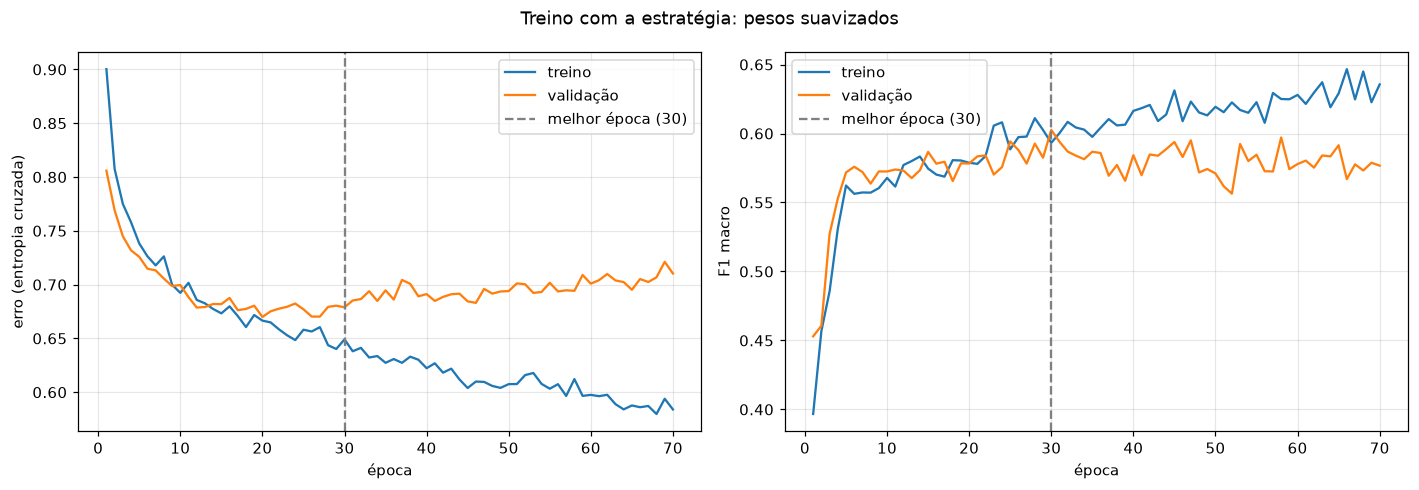

In [38]:
grafico_curvas(historico_final, f"Treino com a estratégia: {melhor_estrategia}", arquivo="2_curvas.png")

O que observar:
- No gráfico da esquerda, os erros de treino e de validação caem juntos até perto da época 20. Depois o erro de treino continua caindo, mas o de validação começa a subir. Esse é o começo do overfitting: a rede passa a decorar detalhes do treino que não valem para vinhos novos.
- No gráfico da direita, o F1 da validação para de melhorar por volta da época 30 (0,603), enquanto o F1 de treino continua subindo até cerca de 0,65.
- O early stopping guardou os pesos da época 30 e parou o treino na época 70. Assim a rede final é a de antes do overfitting.
- As curvas da validação são mais "tremidas" porque a classe baixa tem só 35 vinhos na validação: acertar ou errar 2 ou 3 deles já muda bastante o F1.

## Matriz de confusão no teste

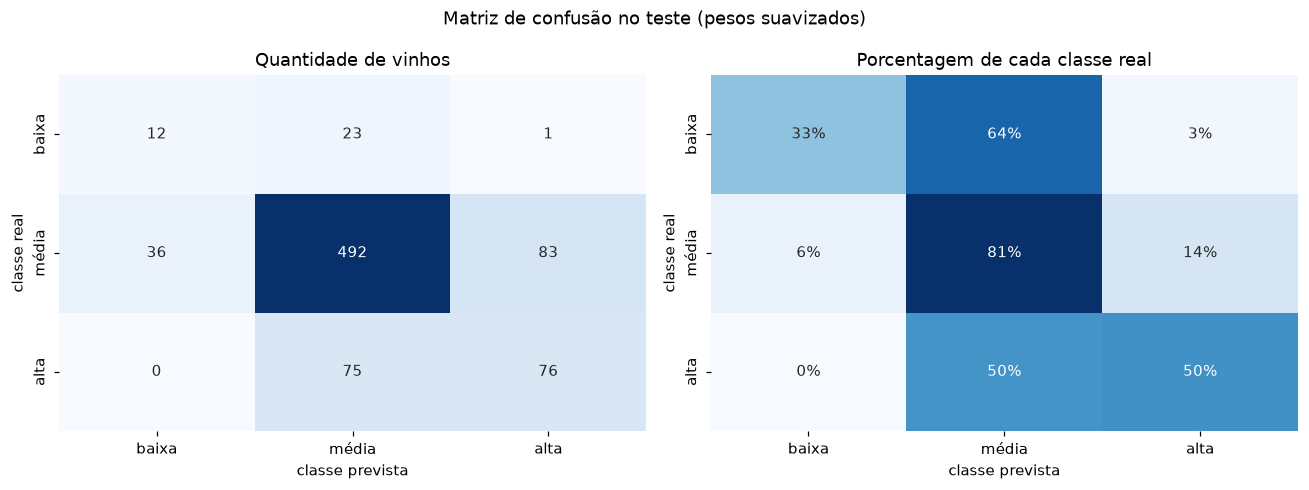

In [39]:
previstos_teste, probabilidades_teste = prever(modelo_final, X_teste_n)
grafico_matriz_confusao(y_teste, previstos_teste, f"Matriz de confusão no teste ({melhor_estrategia})",
                        arquivo="2_matriz_confusao.png")

O que observar:
- Vinhos médios: a rede acerta 81% (492 de 611). Os erros vão mais para "alta" (83) do que para "baixa" (36).
- Vinhos altos: a rede acerta metade (76 de 151). A outra metade é confundida com média. Nenhum vinho alto foi chamado de baixo.
- Vinhos baixos: a rede acerta 33% (12 de 36). A maioria (23) é chamada de média, e só 1 é chamado de alto.
- Quase não há confusão entre baixa e alta (1 caso em 798). Os erros ficam sempre entre classes vizinhas. Isso faz sentido: um vinho de nota 4 é parecido com um de nota 5, e um de nota 7 é parecido com um de nota 6, então a fronteira entre as classes é difícil de achar.

## Métricas no teste

In [40]:
pd.DataFrame([calcular_metricas(y_teste, previstos_teste)], index=["teste"]).round(3)

,acurácia,precisão (macro),recall (macro),F1 (macro)
teste,0.727,0.52,0.547,0.531


## Métricas por classe

In [41]:
print(classification_report(y_teste, previstos_teste, target_names=CLASSES, digits=3))

              precision    recall  f1-score   support

       baixa      0.250     0.333     0.286        36
       média      0.834     0.805     0.819       611
        alta      0.475     0.503     0.489       151

    accuracy                          0.727       798
   macro avg      0.520     0.547     0.531       798
weighted avg      0.740     0.727     0.733       798



O que observar:
- Acurácia de 72,7%: a rede acerta quase 3 de cada 4 vinhos.
- F1 macro de 0,531. A classe média tem F1 de 0,82, a alta 0,49 e a baixa só 0,29.
- A precisão da classe baixa é de 0,25: de cada 4 vinhos que a rede chama de baixo, só 1 realmente é. Isso acontece porque, para encontrar vinhos baixos, a rede acaba marcando também vinhos médios parecidos com eles, e como existem muito mais médios do que baixos, esses alarmes falsos são maioria.
- O F1 macro do teste (0,531) ficou abaixo do da validação (0,603). Isso tem dois motivos:
  - a validação foi usada para escolher a melhor época e a melhor estratégia de balanceamento. Escolhendo pelo melhor resultado na validação, esse resultado tende a ficar um pouco acima do real. O teste, que não participou de nenhuma escolha, mostra o valor mais honesto;
  - com só 36 vinhos baixos no teste, poucos acertos a mais ou a menos mudam muito o F1.

---
# Verificando overfitting

## Métricas em treino, validação e teste
Para o treino usamos os vinhos originais (sem os vinhos artificiais do SMOTE).

In [42]:
tabela_overfitting = {}
for nome, (X_parte, y_parte) in {"treino": (X_treino_n, y_treino), "validação": (X_val_n, y_val), "teste": (X_teste_n, y_teste)}.items():
    previstos, _ = prever(modelo_final, X_parte)
    tabela_overfitting[nome] = calcular_metricas(y_parte, previstos)
pd.DataFrame(tabela_overfitting).T.round(3)

,acurácia,precisão (macro),recall (macro),F1 (macro)
treino,0.783,0.616,0.658,0.634
validação,0.778,0.602,0.604,0.603
teste,0.727,0.520,0.547,0.531


O F1 macro é 0,634 no treino, 0,603 na validação e 0,531 no teste. A acurácia é 78,3%, 77,8% e 72,7%.

Treino e validação estão bem próximos, então a rede não decorou o treino: o early stopping parou antes disso, como vimos nas curvas. A queda maior no teste não é overfitting no treino. Ela vem de a validação ter sido usada para escolher a época e a estratégia (o que deixa o resultado da validação um pouco otimista) e da classe baixa, que tem poucos exemplos (36) e por isso varia muito de um sorteio para outro.

## Comparação com outro modelo
Para ter uma referência, treinamos também uma Random Forest (um conjunto de árvores de decisão), que costuma ir bem em tabelas como esta. Ela recebe os mesmos dados e usa pesos nas classes para lidar com o desbalanceamento.

In [43]:
floresta = RandomForestClassifier(n_estimators=500, class_weight="balanced", min_samples_leaf=3,
                                  random_state=42, n_jobs=-1)
floresta.fit(X_treino_n, y_treino)

pd.DataFrame({
    f"MLP ({melhor_estrategia})": calcular_metricas(y_teste, previstos_teste),
    "Random Forest": calcular_metricas(y_teste, floresta.predict(X_teste_n)),
}).T.round(3)

,acurácia,precisão (macro),recall (macro),F1 (macro)
MLP (pesos suavizados),0.727,0.520,0.547,0.531
Random Forest,0.709,0.517,0.587,0.537


A Random Forest teve F1 macro de 0,537 e acurácia de 70,9%, muito perto da nossa MLP (0,531 e 72,7%). Ou seja, a dificuldade não está na rede: é o problema que é difícil. Com estes atributos químicos, os vinhos de qualidade baixa e alta são muito parecidos com os de qualidade média, como vimos nos boxplots.

---
# Conclusão

Análise e pré-processamento
- A base não tem valores ausentes, mas tinha 1177 vinhos repetidos, que removemos.
- A densidade era redundante (VIF de 20,7, quase uma combinação de álcool e açúcar) e foi removida. Os outros atributos foram mantidos e normalizados.
- As classes são muito desbalanceadas (4% baixa, 77% média, 19% alta), então usamos divisão estratificada e o F1 macro como métrica principal.

Balanceamento
- Sem balanceamento, a rede quase nunca reconhece vinhos ruins (recall de 14%). Então o balanceamento é necessário.
- Testamos pesos nas classes, pesos suavizados e SMOTE. A melhor na validação foi a de pesos suavizados, que equilibra melhor os acertos nas três classes.

Resultado
- Rede com 11 entradas, camadas de 128 e 64 neurônios (ReLU e dropout de 30%) e 3 saídas.
- No teste: acurácia de 72,7%, precisão macro de 0,52, recall macro de 0,55 e F1 macro de 0,53.
- A rede reconhece bem os vinhos médios (81%), metade dos altos e um terço dos baixos. Os erros acontecem quase sempre entre classes vizinhas.
- Não houve overfitting relevante. O early stopping parou o treino quando a validação começou a piorar.
- Uma Random Forest chegou praticamente ao mesmo resultado, o que mostra que o limite está nos dados: só com a química do vinho não dá para separar bem as notas, que também dependem do gosto de quem avaliou.